<a href="https://colab.research.google.com/github/marviiiin/Computer-Vision/blob/main/DL4CV_InstanceSegmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import cv2
import tensorflow as tf
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from tqdm import tqdm
from google.colab.patches import cv2_imshow
from torchvision.models.feature_extraction import create_feature_extractor

9
torch.Size([3, 3, 224, 224]) torch.Size([3, 8, 7, 7]) torch.Size([3, 7, 7, 56, 56])


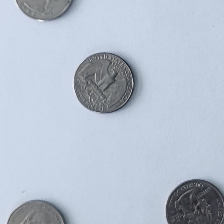

2 3


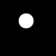

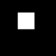

6 6


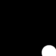

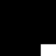

tensor([[0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0]])


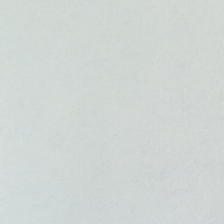

In [ ]:
class Coins(torch.utils.data.Dataset):
    def __init__(self, path, mode):
        self.path = path
        self.images = sorted([x for x in os.listdir(path) if x.endswith('.png')])
        self.mode = mode

        self.t_train = transforms.Compose([
            torchvision.transforms.RandomCrop((224,224))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(os.path.join(self.path, self.images[idx]), cv2.IMREAD_COLOR)
        img = cv2.resize(img, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)
        img = img/255.0
        h, w, _ = img.shape
        img = np.transpose(img, (2,0,1)).astype(np.float32)

        dx = torch.randint(low=0, high=w-224, size=(1,)).item()
        dy = torch.randint(low=0, high=h-224, size=(1,)).item()

        img = torch.from_numpy(img[:, dy:dy+224, dx:dx+224])

        with open(os.path.join(self.path, self.images[idx].replace('.png', '.txt')), 'r') as fp:
            lines = fp.readlines()

        gt = np.zeros((8,7,7), dtype=np.float32) # center_x, center_y, radius, object_conf, prob_1, prob_5, prob_10, prob_25
        mask = np.zeros((7,7,224,224), np.uint8)
        bbox = np.zeros((7,7,224,224), np.uint8)
        for line in lines[1:]:
            x, y, val, r = [int(x) for x in line.split()]
            x = int(x*0.25+0.5) - dx
            y = int(y*0.25+0.5) - dy
            r2 = int(r*1.1*0.25 + 0.5)
            r = int(r*0.25+0.5)

            i = y//32
            j = x//32

            if i >= 0 and i < 7 and j >= 0 and j < 7:
                gt[0,i,j] = (x%32)/31.0
                gt[1,i,j] = (y%32)/31.0
                gt[2,i,j] = r/224.0
                gt[3,i,j] = 1.0
                if val == 1:
                    gt[4,i,j] = 1.0
                elif val == 5:
                    gt[5,i,j] = 1.0
                elif val == 10:
                    gt[6,i,j] = 1.0
                elif val == 25:
                    gt[7,i,j] = 1.0

                cv2.circle(mask[i,j], (x, y), r, (255,255,255), -1)
                cv2.rectangle(bbox[i,j], (x-r2, y-r2), (x+r2, y+r2), (255,255,255), -1)

        mask = mask/255.0
        mask = mask.astype(np.float32)
        mask = torch.from_numpy(mask)
        mask = torchvision.transforms.functional.resize(mask, (56,56))

        bbox = bbox/255.0
        bbox = bbox.astype(np.float32)
        bbox = torch.from_numpy(bbox)
        bbox = torchvision.transforms.functional.resize(bbox, (56,56))

        return img, gt, mask, bbox

train_dataset = Coins('/content/drive/MyDrive/ComputerVision/coins', 'train')
print(len(train_dataset))
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=3, num_workers=3, shuffle=True)

for x, y, z, b in train_dataloader:
  print(x.shape, y.shape, z.shape)

  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
  for i in range(7):
    for j in range(7):
      if y[0,3,i,j] > 0.5:
        print(i,j)
        cv2_imshow(z[0,i,j].numpy()*255.0)
        cv2_imshow(b[0,i,j].numpy()*255.0)
  break


for x, y, z, b in train_dataloader:
  #print(y[:,4:].argmax(dim=1))
  w = y[:,4:].argmax(dim=1)

  # batch visualization
  for j in range(len(x)):
    print(w[j])
    # convert pixel color to 0-255
    img = (x[j].numpy().transpose((1,2,0))*255.0).astype(np.uint8).copy()
    for ki in range(7):
      for kj in range(7):
        k = ki*7+kj
        px, py, pr, pc, p1, p5, p10, p25 = y[j,:,k//7,k%7]
        if pc.item() > 0.5:
          print(px, py, pr, pc, p1, p5, p10, p25)
          # center of bounding box
          cx = (k%7)*32 + int(px*31+0.5)
          cy = (k//7)*32 + int(py*31+0.5)
          # dimensions of bounding box
          r = int(pr*224+0.5)
          print(pc.item(), cx, cy, r)
          cv2.circle(img, (cx,cy), r, (0,255,0), 1)
    cv2_imshow(img)
    break
  break

0 0.35917102297147113 0.008168651722371578 1.4045985142389934 0.0024786669140060744
1 0.17158793906370798 0.003368453433116277 1.3895634412765503 0.00216922874096781
2 0.1315768559773763 0.0034443364711478353 1.378879229227702 0.0021282437179858484
3 0.13437808801730475 0.003784141813715299 1.3758515516916912 0.0021988049459954104
4 0.12123001056412856 0.004941346667086084 1.3756566445032756 0.0020438437641132623
5 0.11621101573109627 0.002989300371458133 1.3732889890670776 0.0019604051873708763
6 0.10605711211125406 0.0022253793043394885 1.3706670602162678 0.0020431552547961473
7 0.10991717132886454 0.0023872113476196923 1.3665850162506104 0.002177004391948382
8 0.09039010852575302 0.0029144653429587684 1.3636315663655598 0.0019803246056350567
9 0.0710704264541467 0.002344110883617153 1.371073842048645 0.0017121528217103332
tensor(0.5161) tensor(0.3226) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 16 42 22
tensor(0.3626, device='cuda:0', grad_fn=<UnbindBac

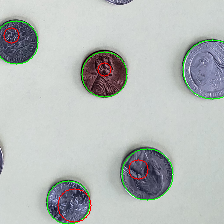

1 0


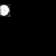

2 3


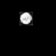

2 6


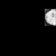

5 4


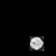

6 2


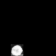

tensor(0.0968) tensor(0.6129) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 99 19 23
tensor(0.7742) tensor(0.6452) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 152 20 22
tensor(0.4516) tensor(0.8387) tensor(0.1205) tensor(1.) tensor(0.) tensor(1.) tensor(0.) tensor(0.)
1.0 206 26 27
tensor(0.5074, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5632, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1909, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5490, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.4896, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.4125, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.9391, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.8841, device='cuda:0', grad_fn=<UnbindBackward0>)
0.548961877822876 208 17 43
tensor(0.4194) tensor(0.8710) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 45 91 23
tensor(0.3880, device='cuda:0', grad_fn=<U

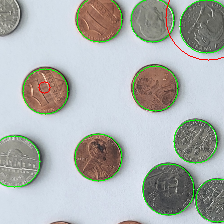

0 3


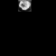

0 4


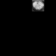

0 6


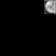

2 1


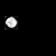

2 4


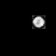

4 3


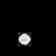

4 6


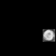

5 0


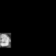

5 5


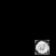

6 6


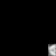

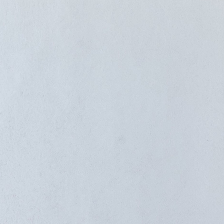

10 0.07530830365916093 0.0010300120047759265 1.351201335589091 0.0018026887749632199
11 0.07132816341860841 0.004014825807341064 1.3535348971684773 0.0017259209610832234
12 0.06650343366588156 0.002678802120499313 1.3634869654973347 0.001627813132169346
13 0.058433533956607185 0.0021733459240446487 1.3679490486780803 0.0015937562566250563
14 0.04689980112016201 0.001935400456810991 1.348671793937683 0.0015338374651037157
15 0.048629588137070336 0.0015651009938058753 1.3482842048009236 0.0016499586636200547
16 0.04508894387011727 0.0017242570174857974 1.3641941944758098 0.001717905979603529
17 0.035148462591071926 0.0013730860470483701 1.3659801085789998 0.0014912776726608474
18 0.05504042748361826 0.001904923323309049 1.3505534728368123 0.0015811995932987581
19 0.10577867552638054 0.002049029969687884 1.3499614000320435 0.002630998923753699
tensor(0.4839) tensor(0.7097) tensor(0.1161) tensor(1.) tensor(0.) tensor(1.) tensor(0.) tensor(0.)
1.0 111 86 26
tensor(0.3589, device='cuda:0', g

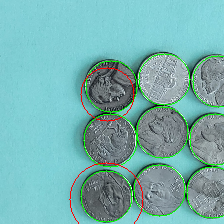

2 3


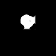

2 5


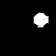

2 6


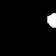

4 3


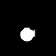

4 5


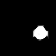

4 6


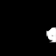

5 4


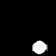

6 3


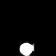

6 6


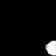

tensor(0.1613) tensor(0.1935) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 5 6 23
tensor(0.) tensor(0.3871) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 128 12 24
tensor(0.2422, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3762, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0775, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5256, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.2229, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.8892, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5526, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.8490, device='cuda:0', grad_fn=<UnbindBackward0>)
0.5256328582763672 136 12 17
tensor(0.8065) tensor(0.1935) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 217 6 24
tensor(0.6174, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3517, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1050, device='cuda:0', grad_fn=<Unb

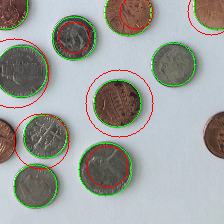

0 0


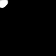

0 4


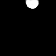

0 6


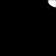

1 2


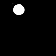

2 0


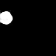

2 5


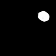

3 3


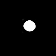

4 1


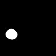

5 1


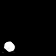

5 3


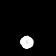

tensor(0.9677) tensor(0.2581) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 126 8 30
tensor(0.9311, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1063, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0504, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.8541, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.2537, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-2.9588, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.7247, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(2.9340, device='cuda:0', grad_fn=<UnbindBackward0>)
0.8541465997695923 125 3 11
tensor(0.0323) tensor(0.1935) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 65 102 23
tensor(0.2581) tensor(0.1935) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 168 166 30
tensor(0.1984, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0652, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0130, device='cuda:0', grad_

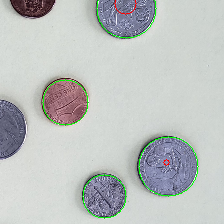

0 3


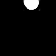

3 2


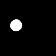

5 5


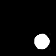

6 3


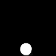

20 0.055950927858551346 0.0016146558530939121 1.3470614353815715 0.0016161999277149637
21 0.04307801276445389 0.0015744888805784285 1.3522653182347615 0.0018431127731067438
22 0.04614966797331969 0.0011876662417004507 1.3446064790089924 0.0016040873209324975
23 0.057870895912249885 0.0014092484198044986 1.3360248804092407 0.0016644304074967902
24 0.040457939729094505 0.0015413245904104163 1.3739949862162273 0.0021023735559235015
25 0.03161192910435299 0.0006084802201561009 1.3492613633473713 0.001733814210941394
26 0.03880282460401455 0.0015186896101416398 1.3398367961247761 0.0018663009395822883
27 0.05177450614670912 0.0011056902003474534 1.3478975296020508 0.001591906378356119
28 0.044871592273314796 0.0013689178934631248 1.3331354856491089 0.001764336562094589
29 0.06409112239877383 0.0011342284124111757 1.3328545888264973 0.0019582238649794212
tensor(0.9827, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5106, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0620, device

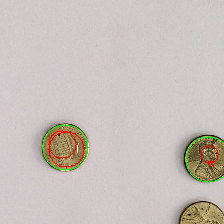

4 2


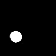

4 6


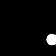

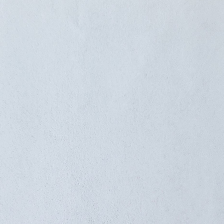

tensor(0.0968) tensor(0.6452) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 35 20 30
tensor(0.1674, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.7540, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0807, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9793, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.3879, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-2.5767, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.8062, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(2.4148, device='cuda:0', grad_fn=<UnbindBackward0>)
0.9792592525482178 37 23 18
tensor(0.3548) tensor(0.9677) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 171 30 30
tensor(0.3123, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.8359, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0953, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5302, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.0583, device='cuda:0', g

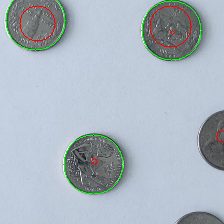

0 1


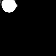

0 5


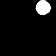

5 2


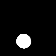

30 0.056386638432741165 0.0022540538338944316 1.3459445238113403 0.00216582448532184
31 0.014505810414751371 0.0009973234264180064 1.325664480527242 0.0018336176872253418
32 0.04738686482111613 0.0009172868352228155 1.335371494293213 0.0015304962871596217
33 0.047044689456621804 0.0007770647886597241 1.3506340980529785 0.0015951266250340268
34 0.03027821734819251 0.0008671725760602081 1.3456101417541504 0.0017909470867986481
35 0.019873545039445162 0.0007831325832133492 1.3360291719436646 0.0016089672960030537
36 0.024396083791240624 0.0009973810811061412 1.3530581792195637 0.0013753748110805948
37 0.04025947488844395 0.000987727757698546 1.329292853673299 0.0022757392143830657
38 0.038504572585225105 0.0008400816974850992 1.3394622008005779 0.0016517267019177477
39 0.025144111054639023 0.0005180972608892868 1.332463026046753 0.0015068503756386538
tensor(0.9370, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.2807, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1703, device=

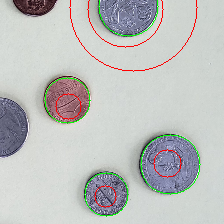

0 4


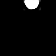

3 2


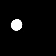

5 5


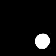

6 3


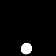

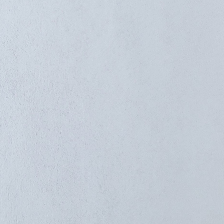

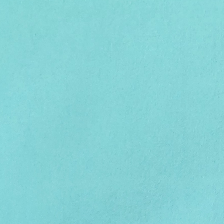

40 0.05728217911731311 0.002190826923955077 1.3311452468236287 0.00216300353834716
41 0.03643848809103171 0.0007567729553557001 1.3329981962839763 0.0016494101340261598
42 0.025013581655609112 0.0007931313690884659 1.326504389444987 0.0015853976171153288
43 0.03101342000688116 0.000511961387625585 1.33480437596639 0.001619377968988071
44 0.019108374050119892 0.0006893894557530681 1.3363097111384075 0.0017164093248235683
45 0.026422474290257014 0.0006495615816675127 1.3318910598754883 0.0013973151023189228
46 0.020898278783230733 0.0007441100897267461 1.3233689467112224 0.0019943832157878205
47 0.009524130713543855 0.00039285524659741594 1.3293322324752808 0.0015874012218167384
48 0.017573026319344837 0.0007021972366298238 1.3181089560190837 0.0017671492726852496
49 0.02106462698429823 0.0008219576363141338 1.330840826034546 0.0018982880283147097
tensor(0.4516) tensor(0.5806) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 142 50 24
tensor(0.6527, device='cuda:

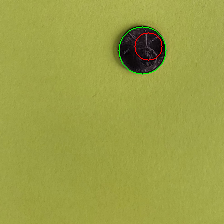

1 4


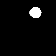

tensor(0.1613) tensor(0.5484) tensor(0.1161) tensor(1.) tensor(0.) tensor(1.) tensor(0.) tensor(0.)
1.0 37 17 26
tensor(0.2497, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5442, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1338, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9977, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9964, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.1850, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.7294, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.7692, device='cuda:0', grad_fn=<UnbindBackward0>)
0.997700035572052 40 17 30
tensor(0.6452) tensor(0.2581) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 116 72 24
tensor(0.8158, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0953, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0900, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9998, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(4.9683, device='cuda:0', gra

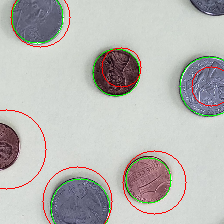

0 1


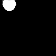

2 3


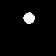

2 6


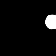

5 4


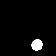

6 2


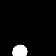

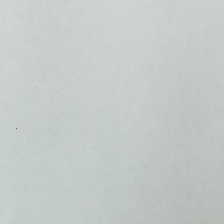

50 0.021673767286605045 0.0004525450755560693 1.344286322593689 0.0013955288547246407
51 0.04955132119357586 0.0005869510108216976 1.337317665417989 0.001577960792928934
52 0.026876311904440325 0.00109686156307968 1.3283897638320923 0.0016338129450256627
53 0.035084142039219536 0.0006874724106940752 1.3301554918289185 0.0014827926643192768
54 0.03991882697058221 0.0008548410611789828 1.324314792950948 0.0015961616882123053
55 0.024116224226114962 0.0007188598344024891 1.3416706720987956 0.0014610642295641203
56 0.01246852862338225 0.0004519434248019631 1.3199607133865356 0.0015825804245347779
57 0.01213594083674252 0.0005704131229625394 1.3282210032145183 0.001531404258760934
58 0.01215996090710784 0.0006368502120797833 1.3157166242599487 0.0018379422059903543
59 0.012414077180437744 0.0005843678178886572 1.323277235031128 0.001641418367701893
tensor(0.) tensor(0.0645) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 96 162 23
tensor(0.1500, device='cuda:0', gr

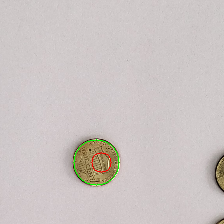

5 3


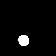

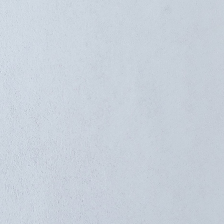

tensor(0.8387) tensor(0.1613) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 186 197 24
tensor(0.9437, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0470, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0368, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9921, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(4.0179, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-3.0965, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.9289, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-2.4364, device='cuda:0', grad_fn=<UnbindBackward0>)
0.9921187162399292 189 193 8


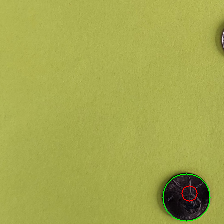

6 5


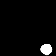

60 0.020316421675185364 0.0006614027176207552 1.337961196899414 0.0015956650798519452
61 0.02397308098928382 0.0003724702352580304 1.3404157956441243 0.001584061615479489
62 0.0435856116926819 0.0008771346183493733 1.339163343111674 0.0016253951471298933
63 0.01507002922395865 0.0003741991192024822 1.326682686805725 0.0016258334508165717
64 0.04828179472436508 0.00040222165019561845 1.3331228097279866 0.0016969611557821433
65 0.0352170222128431 0.000399357906038252 1.3167242209116619 0.0017833559152980645
66 0.013360381902505955 0.00044555135536938906 1.3320581118265789 0.0014707727629380922
67 0.011780964521070322 0.0005806916257521758 1.3184114694595337 0.001650132491098096
68 0.02071013945078448 0.000465629144552319 1.3169701099395752 0.001985234693468859
69 0.012025662793651767 0.00042627200794716674 1.3219205141067505 0.0014721311163157225


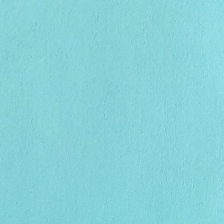

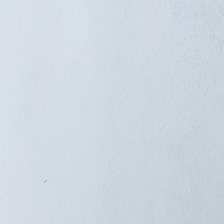

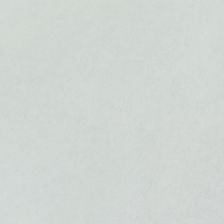

70 0.030438818503171206 0.0005990916591448089 1.3234748045603435 0.0015619087886686127
71 0.027981575539646048 0.0003744201555188435 1.3296479384104412 0.0014026011534345646
72 0.01635522961926957 0.0004608856640212859 1.3396857182184856 0.001359864914168914
73 0.017788481898605824 0.00038846325090465445 1.3229901790618896 0.0016614894654291372
74 0.0721056946980146 0.0012941389528956886 1.31107230981191 0.0017494142812211066
75 0.03157494765279504 0.0004047467518830672 1.331323464711507 0.0013681189739145339
76 0.031151088575522106 0.00039790302980691195 1.334776480992635 0.0014707702697099496
77 0.011913480741592744 0.0004433586946106516 1.3272842168807983 0.0015920724254101515
78 0.03339382540434599 0.0012276949128136039 1.320459286371867 0.0016891369984174769
79 0.05517375593384107 0.0011832155869342387 1.2928799788157146 0.0025309306026125946


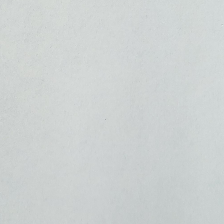

tensor(0.3548) tensor(0.8065) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 11 25 30
tensor(0.3016, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.7592, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1263, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9722, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-3.0992, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.1703, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-3.6965, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(2.6933, device='cuda:0', grad_fn=<UnbindBackward0>)
0.9722265601158142 9 24 28
tensor(0.2258) tensor(0.1613) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 199 5 30
tensor(0.2628, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.2634, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0953, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.8951, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-5.2345, device='cuda:0', gra

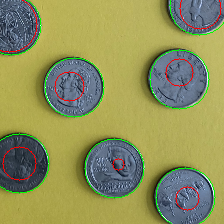

0 0


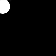

0 6


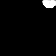

2 2


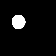

2 5


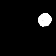

5 0


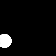

5 3


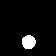

6 5


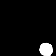

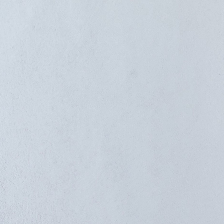

80 0.011568849646816185 0.0004149416272412054 1.334698756535848 0.001662592568512385
81 0.027153500355780125 0.0003066452342560903 1.3424028555552165 0.0014869592462976773
82 0.0281018636499842 0.0007809115146907667 1.3430894613265991 0.001922059222124517
83 0.023709872737526894 0.00044675677418126725 1.3330006996790569 0.0015679886758637924
84 0.031951323772470154 0.0009523216625287508 1.3448915084203084 0.0016190637834370136
85 0.023080648854374886 0.000591747045594578 1.328545093536377 0.0017323650342101853
86 0.04006276838481426 0.0007826381576402733 1.3152868350346882 0.001984899863600731
87 0.01105447401641868 0.00034801003069636255 1.3316322962443035 0.001553264194323371
88 0.03925704831878344 0.000594529209289855 1.3188947836558025 0.0016649867175146937
89 0.03047801854457551 0.0006016713741701096 1.322317083676656 0.0016031337436288595
tensor(0.7419) tensor(0.) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 119 0 30
tensor(0.6224, device='cuda:0', gr

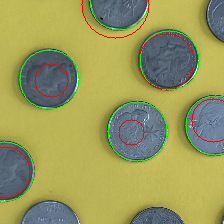

0 3


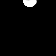

1 5


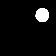

2 1


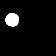

3 6


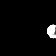

4 4


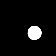

5 0


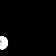

tensor(0.4516) tensor(0.4194) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 78 13 22
tensor(0.5839, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5753, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0865, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9936, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.7218, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.2863, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(1.3291, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-4.0506, device='cuda:0', grad_fn=<UnbindBackward0>)
0.993561863899231 82 18 19
tensor(1.) tensor(0.4194) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 191 13 22
tensor(0.2366, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3932, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1986, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5887, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3155, device='cuda:0', grad_fn=

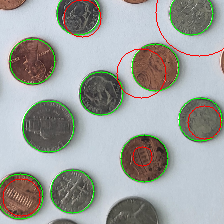

0 2


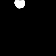

0 5


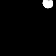

1 1


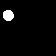

2 3


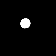

2 4


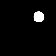

3 1


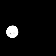

3 6


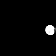

4 4


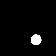

5 2


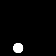

6 0


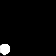

tensor(0.5484) tensor(0.0645) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 177 2 22
tensor(1.) tensor(0.5484) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 63 81 23
tensor(0.1935) tensor(0.8065) tensor(0.1295) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 134 121 29
tensor(0.0958, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9057, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1190, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9984, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-3.8598, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.5849, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-4.4816, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(4.8581, device='cuda:0', grad_fn=<UnbindBackward0>)
0.9983602166175842 131 124 27
tensor(0.) tensor(0.2903) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 0 201 30
tensor(0.1836, device='cuda:0', grad_fn=<UnbindBac

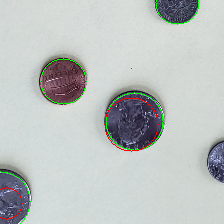

0 5


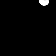

2 1


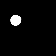

3 4


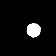

6 0


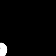

90 0.009947326655189196 0.00046813907586814213 1.3210848967234294 0.0015367647671761613
91 0.027631894995768864 0.0008683556128138056 1.3107997973759968 0.002073915869308015
92 0.023425658243165042 0.00046235284632227075 1.310052474339803 0.001961897845224788
93 0.021828396013006568 0.0006731366350625952 1.322026292483012 0.0015353006698812048
94 0.03724757504339019 0.001656390353067157 1.3092243671417236 0.002385577419772744
95 0.04090861727794012 0.0006263134224961201 1.3242558240890503 0.0014945780858397484
96 0.020931573274234932 0.0008139184986551603 1.3149051666259766 0.0015823441790416837
97 0.03609628789126873 0.0008187141502276063 1.2985194126764934 0.0019896310210848847
98 0.010482439688833741 0.0005285346414893866 1.334794561068217 0.0014545161199445527
99 0.02620718065766899 0.0011265433058724739 1.2952080965042114 0.0020072547146507227
tensor(0.1613) tensor(0.2581) tensor(0.1071) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 133 104 24
tensor(0.0466, device='c

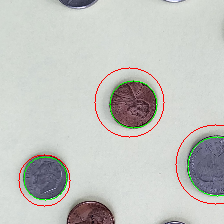

3 4


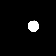

5 1


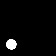

5 6


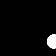

tensor(0.4194) tensor(0.0323) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 205 1 30
tensor(0.3536, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0769, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1302, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.8195, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-2.8487, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.6139, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-0.7918, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(3.0420, device='cuda:0', grad_fn=<UnbindBackward0>)
0.8195334076881409 203 2 29
tensor(0.1935) tensor(0.9355) tensor(0.1339) tensor(1.) tensor(0.) tensor(0.) tensor(0.) tensor(1.)
1.0 70 61 30
tensor(0.1073, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9380, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1117, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9992, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-5.0464, device='cuda:0', gr

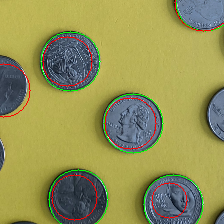

0 6


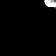

1 2


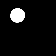

3 4


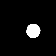

6 2


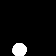

6 5


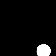

tensor(0.4839) tensor(0.) tensor(0.1027) tensor(1.) tensor(1.) tensor(0.) tensor(0.) tensor(0.)
1.0 47 0 23
tensor(0.7742) tensor(0.5484) tensor(0.1161) tensor(1.) tensor(0.) tensor(1.) tensor(0.) tensor(0.)
1.0 216 17 26
tensor(0.6664, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3810, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1122, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.9105, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-3.0105, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.3450, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(-1.3105, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.2090, device='cuda:0', grad_fn=<UnbindBackward0>)
0.9104836583137512 213 12 25
tensor(0.2258) tensor(0.0645) tensor(0.0982) tensor(1.) tensor(0.) tensor(0.) tensor(1.) tensor(0.)
1.0 103 34 22
tensor(0.4831, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.1118, device='cuda:0', grad_fn=<UnbindBackward0>) tensor(0.0648, device='cuda:0', grad_fn=<Un

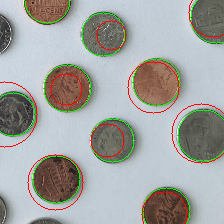

0 1


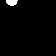

0 6


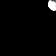

1 3


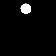

2 2


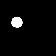

2 4


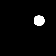

3 0


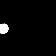

4 3


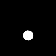

4 6


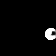

5 1


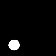

6 5


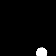

Finished Training


In [ ]:
class Detector(torch.nn.Module):
    def __init__(self):
        super().__init__()

        resnet = torchvision.models.resnet18(weights='DEFAULT')
        return_nodes = { 'layer1': 'layer1', 'layer4': 'layer4'}
        self.featmap = feat_model = create_feature_extractor(resnet, return_nodes=return_nodes)
        self.n_prot = 16
        self.fc = torch.nn.Linear(512, 8 + self.n_prot)
        self.conv1 = torch.nn.Conv2d(64, 64, 3, padding='same')
        self.conv2 = torch.nn.Conv2d(64, 64, 3, padding='same')
        self.conv3 = torch.nn.Conv2d(64, self.n_prot, 3, padding='same')

    def forward(self, x):
        x = self.featmap(x)
        hr = x['layer1']
        lr = x['layer4']

        bs, fs, h, w = lr.size()
        x = lr.permute(0,2,3,1).reshape(bs*h*w, fs)
        x = self.fc(x)
        x = x.reshape(bs, h, w, 8 + self.n_prot).permute(0,3,1,2)
        x[:,:4,:,:] = torch.sigmoid(x[:,:4,:,:])
        w = x[:,8:]
        x = x[:,:8]

        y = torch.nn.functional.relu(self.conv1(hr))
        y = torch.nn.functional.relu(self.conv2(y))
        y = self.conv3(y) # 1x16x56x56

        w = w.permute(0,2,3,1).reshape((bs,49,self.n_prot)) # BSx49x16
        y = y.reshape((bs,self.n_prot,56*56))

        masks = torch.sigmoid(torch.bmm(w, y).reshape((bs,7,7,56,56)))

        return x, masks

model = Detector().cuda()
model.eval()

dummy_input = torch.zeros((1,3,224,224)).cuda()
with torch.no_grad():
  out = model(dummy_input)

criterion = torch.nn.BCELoss()
criterion2 = torch.nn.CrossEntropyLoss()
criterion3 = torch.nn.BCEWithLogitsLoss(reduction='none')
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

for i in range(100):
  l1 = 0
  l2 = 0
  l3 = 0
  l4 = 0
  total = 0
  for x, y, z, b in train_dataloader:
    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs, masks = model(x.cuda())

    loss_confidence = criterion(outputs[:,3], y[:,3].cuda())
    loss_bbox = torch.mean(torch.mean(torch.nn.functional.mse_loss(outputs[:,:3], y[:,:3].cuda(), reduction='none'), dim=1) * y[:,3].cuda())
    loss_class = criterion2(outputs[:,4:] * y[:,3:4].cuda(), y[:,4:].argmax(dim=1).cuda())

    # instance segmentation loss
    #loss_segmentation = criterion(masks*b.cuda(), z.cuda())
    loss_segmentation = torch.mean(criterion3(masks, z.cuda())*b.cuda())


    loss = loss_confidence + 10.0 * loss_bbox + loss_class + loss_segmentation
    loss.backward()
    optimizer.step()

    l1 += loss_confidence.item()
    l2 += loss_bbox.item()
    l3 += loss_class.item()
    l4 += loss_segmentation.item()
    total += 1

  print(i, l1/total, l2/total, l3/total, l4/total)

  if i%10 == 9:
    # batch visualization
    for j in range(len(x)):
      # convert pixel color to 0-255
      img = (x[j].numpy().transpose((1,2,0))*255.0).astype(np.uint8).copy()
      for ki in range(7):
        for kj in range(7):
          k = ki*7+kj
          px, py, pr, pc, p1, p5, p10, p25 = y[j,:,k//7,k%7]
          if pc.item() > 0.5:
            print(px, py, pr, pc, p1, p5, p10, p25)
            # center of bounding box
            cx = (k%7)*32 + int(px*31+0.5)
            cy = (k//7)*32 + int(py*31+0.5)
            # dimensions of bounding box
            r = int(pr*224+0.5)
            print(pc.item(), cx, cy, r)
            cv2.circle(img, (cx,cy), r, (0,255,0), 1)

          px, py, pr, pc, p1, p5, p10, p25 = outputs[j,:,k//7,k%7]
          if pc.item() > 0.5:
            print(px, py, pr, pc, p1, p5, p10, p25)
            # center of bounding box
            cx = (k%7)*32 + int(px*31+0.5)
            cy = (k//7)*32 + int(py*31+0.5)
            # dimensions of bounding box
            r = int(pr*224+0.5)
            print(pc.item(), cx, cy, r)
            cv2.circle(img, (cx,cy), r, (0,0,255), 1)

      cv2_imshow(img)
      for ki in range(7):
        for kj in range(7):
          if y[j,3,ki,kj] > 0.5:
            print(ki,kj)
            cv2_imshow(b[j,ki,kj].numpy()*masks[j,ki,kj].detach().cpu().numpy()*255.0)

print('Finished Training')